# Arrhythmia Classification Based on Photoplethysmography Signals

## Preliminaries

In [1]:
!pip -q install ai-edge-litert

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 13.6 MB/s eta 0:00:00


In [2]:
import glob
import json
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pywt
import seaborn as sns
import tensorflow as tf
from ai_edge_litert.interpreter import Interpreter
from scipy.fft import fft
from scipy.signal import butter, find_peaks, resample, sosfilt
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import Concatenate, Conv1D, Dense, GRU, Input, MaxPooling1D, Reshape
from tensorflow.keras.models import Model, Sequential, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

## Download PPG Dataset

In [3]:
!gdown -q 1MMMeESIapJovDZgT6a-wbpsvlfZ1IOef

In [8]:
ppg_df = pd.read_json('/content/PPG_DATASET_4CLASS_SEGMENT_250Hz.json', lines=True)

In [9]:
ppg_df.head()

,ppg_signal,frequency,label
0,"[3115.0, 3528.0, 3115.0, 2899.0, 3115.0, 3244....",250,Bradycardia
1,"[3279.0, 3275.0, 3279.0, 3275.0, 3279.0, 3275....",250,Bradycardia
2,"[3197.0, 3193.0, 3197.0, 3194.0, 3197.0, 3192....",250,Bradycardia
3,"[4180.0, 4152.0, 4139.0, 4133.0, 4139.0, 4122....",250,Bradycardia
4,"[3279.0, 3275.0, 3279.0, 3275.0, 3279.0, 3275....",250,Bradycardia


## Resampling Signal

In [10]:
def resample_signal(ppg_signal, original_rate, target_rate):
    # Convert to numeric list
    ppg_signal = list(np.array(ppg_signal, dtype=np.float32))

    # Calculate target duration and length
    original_length = len(ppg_signal)
    duration_seconds = original_length / original_rate
    target_length = int(duration_seconds * target_rate)

    return resample(ppg_signal, target_length)

In [11]:
# CHANGE THIS !!!
SAMPLING_RATE_ORIGIN = 250
SAMPLING_RATE_TARGET = 200

# Apply to the entire dataframe
ppg_df['ppg_signal_resampled'] = ppg_df.apply(
    lambda row: resample_signal(row['ppg_signal'], SAMPLING_RATE_ORIGIN, SAMPLING_RATE_TARGET), axis=1
)

# Update sampling_rate
ppg_df['frequency'] = SAMPLING_RATE_TARGET

ppg_df = ppg_df.drop(columns=['ppg_signal'])
ppg_df = ppg_df.rename(columns={'ppg_signal_resampled': 'ppg_signal'})
ppg_df = ppg_df[['ppg_signal', 'frequency', 'label']]

ppg_df.head()

,ppg_signal,frequency,label
0,"[3188.0981, 3453.5796, 2939.3435, 3048.354, 32...",200,Bradycardia
1,"[3269.0078, 3279.666, 3275.4924, 3278.0352, 32...",200,Bradycardia
2,"[3294.298, 3161.627, 3214.4055, 3182.5376, 320...",200,Bradycardia
3,"[4086.8796, 4179.051, 4117.047, 4149.1665, 411...",200,Bradycardia
4,"[3277.1252, 3276.956, 3277.026, 3276.9802, 327...",200,Bradycardia


## Signal Preprocessing

### Band Pass Filter

In [12]:
def bandpass_filter(signal, fs, lowcut, highcut, order):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    sos = butter(order, [low, high], btype='bandpass', output='sos')
    return sosfilt(sos, signal)

### Moving Average Filter

In [13]:
def moving_average_filter(signal, window_size):
    window = np.ones(window_size) / window_size
    return np.convolve(signal, window, mode='same')

### Normalization

In [14]:
def normalize_signal(signal, method):
    signal = np.array(signal).astype(np.float32)
    if method == 'minmax':
        return ((signal - np.min(signal)) / (np.max(signal) - np.min(signal) + 1e-6))
    elif method == 'zscore':
        return ((signal - np.mean(signal)) / (np.std(signal) + 1e-6))
    else:
        raise ValueError("Normalization method not supported")

### Apply Band Pass Filter, Moving Average, and Normalization

In [15]:
def preprocess_ppg_signal(row, norm_method='minmax', ma_window=5):
    signal = row['ppg_signal']
    fs = SAMPLING_RATE_TARGET

    filtered = bandpass_filter(signal, fs, lowcut=0.5, highcut=5, order=2)
    smoothed = moving_average_filter(filtered, window_size=ma_window)
    normalized = normalize_signal(smoothed, method=norm_method)

    return normalized

In [16]:
# Apply to the entire DataFrame (add new column)
ppg_df['ppg_signal_processed'] = ppg_df.apply(lambda row: preprocess_ppg_signal(row), axis=1)

### Plot Signal After Preprocessing

In [17]:
def plot_ppg_signal(title, signal, start_time, end_time):
    fs = SAMPLING_RATE_TARGET

    start_signal_index = int(start_time * fs)
    end_signal_index = int(end_time * fs)

    signal_segment = signal[start_signal_index:end_signal_index]
    t = np.arange(len(signal_segment)) / fs

    plt.figure(figsize=(16, 4))
    plt.plot(t, signal_segment, label='PPG Signal')
    plt.xlabel('Time (s)')
    plt.ylabel('A.U.')
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.show()

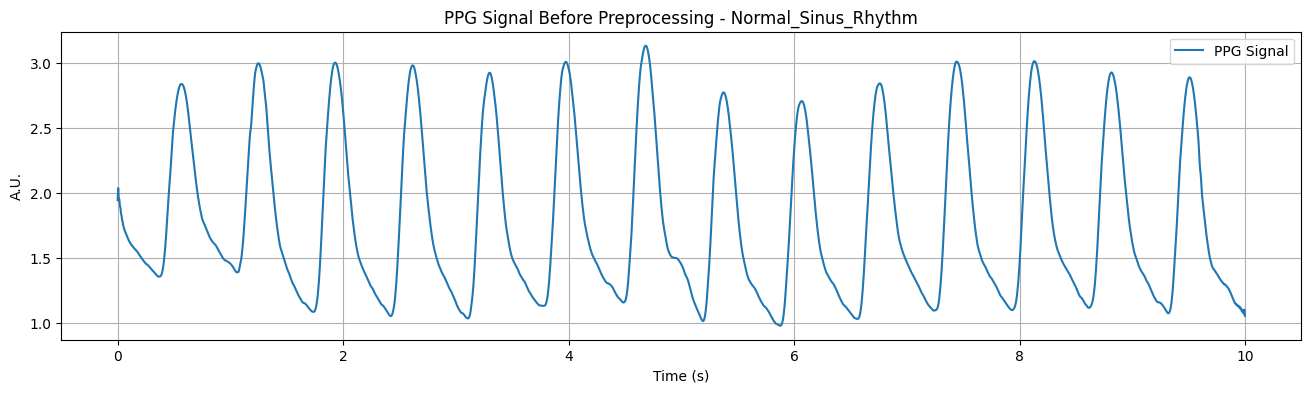

In [18]:
filename = ppg_df['label'].iloc[3266]
title = f'PPG Signal Before Preprocessing - {filename}'
signal = ppg_df['ppg_signal'].iloc[3266]

plot_ppg_signal(title, signal, 0, 10)

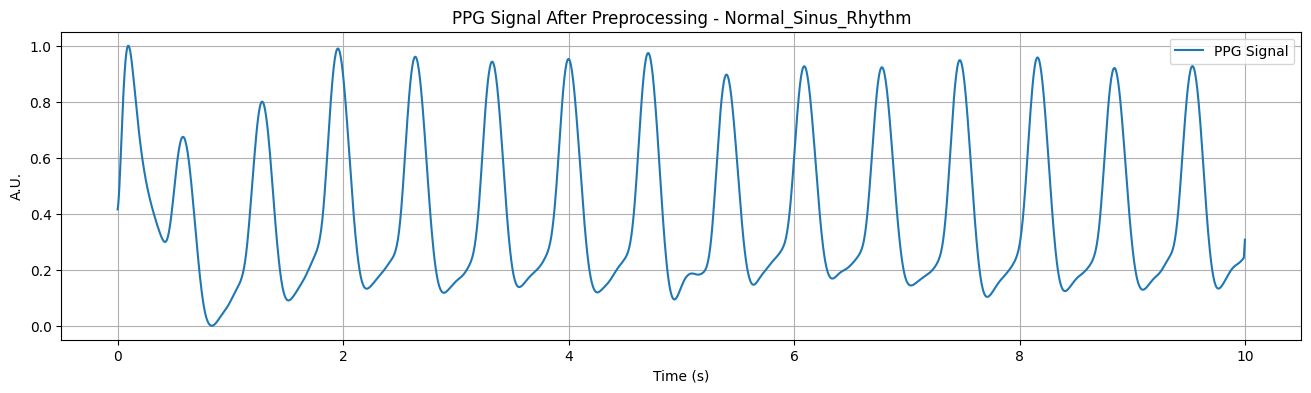

In [19]:
filename = ppg_df['label'].iloc[3266]
title = f'PPG Signal After Preprocessing - {filename}'
signal = ppg_df['ppg_signal_processed'].iloc[3266]

plot_ppg_signal(title, signal, 0, 10)

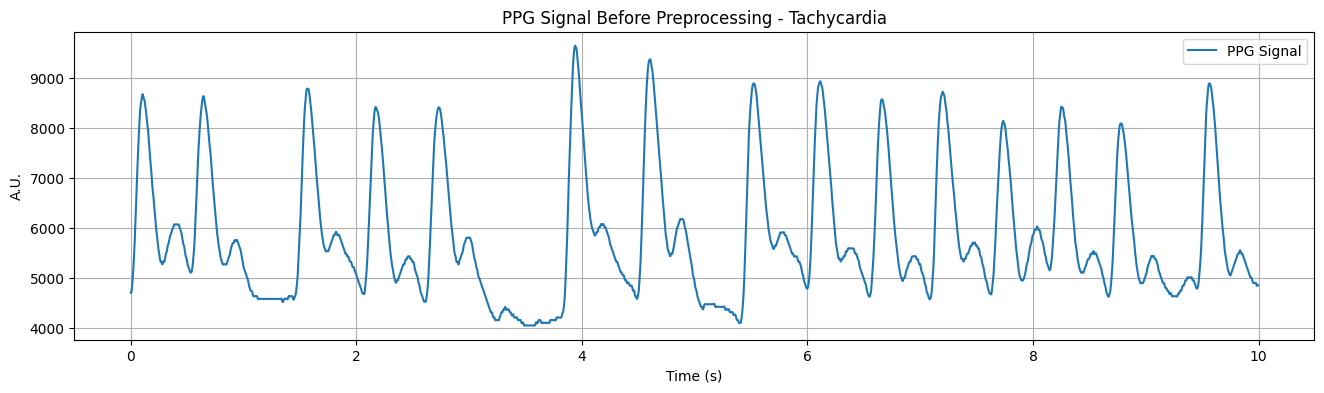

In [20]:
filename = ppg_df['label'].iloc[4846]
title = f'PPG Signal Before Preprocessing - {filename}'
signal = ppg_df['ppg_signal'].iloc[4846]

plot_ppg_signal(title, signal, 0, 10)

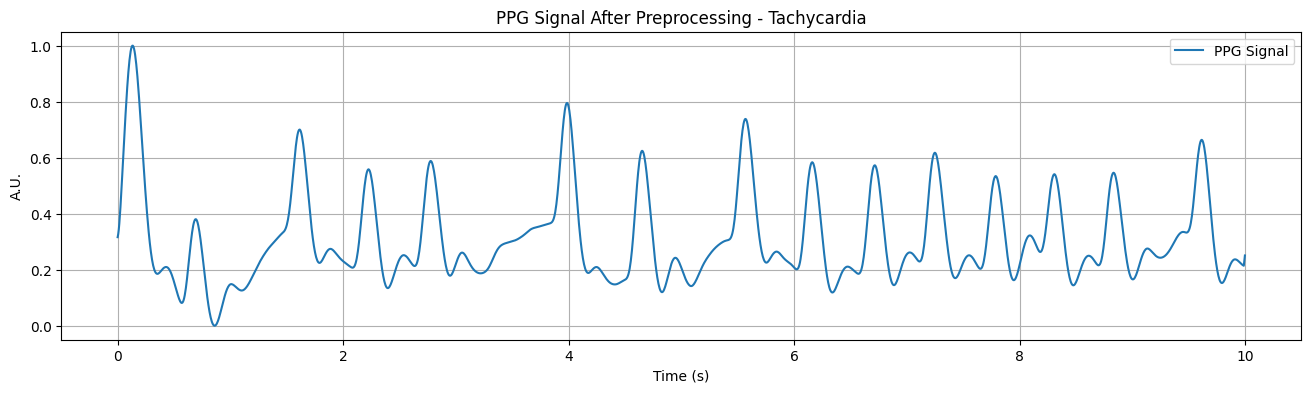

In [21]:
filename = ppg_df['label'].iloc[4846]
title = f'PPG Signal After Preprocessing - {filename}'
signal = ppg_df['ppg_signal_processed'].iloc[4846]

plot_ppg_signal(title, signal, 0, 10)

## Feature Extraction

In [22]:
def list_of_segments(df):
    segments = []

    for _, row in df.iterrows():
        segments.append({
            'ppg_segment': row['ppg_signal_processed'],
            'frequency': row['frequency'],
            'label': row['label']
        })

    return segments

In [23]:
ppg_segments = list_of_segments(ppg_df)

### Discrete Wavelet Transform

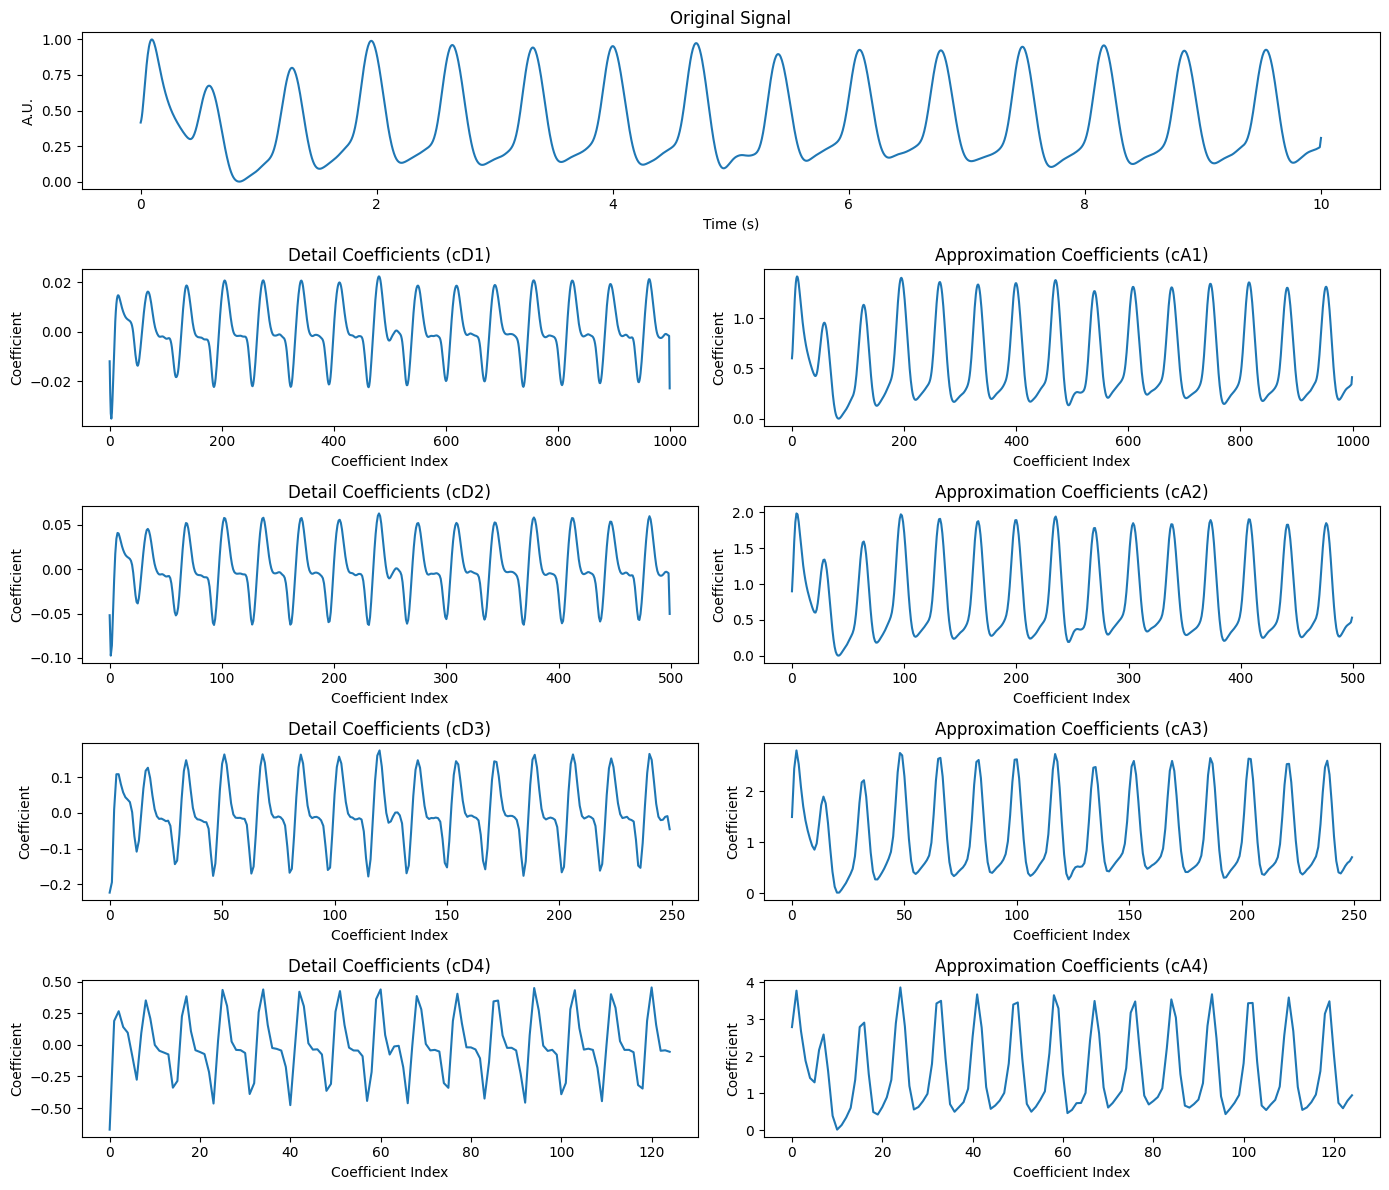

In [24]:
signal = ppg_segments[3266]['ppg_segment']
fs = SAMPLING_RATE_TARGET
duration = len(signal) / fs
time = np.linspace(0, duration, len(signal))

# DWT level 4 decomposition
wavelet = 'db1'
level = 4
coeffs = pywt.wavedec(signal, wavelet, level=level)
# coeffs = [cA4, cD4, cD3, cD2, cD1]
cA4, cD4, cD3, cD2, cD1 = coeffs

# Approximation level 1-3
cA3 = pywt.wavedec(signal, wavelet, level=3)[0]
cA2 = pywt.wavedec(signal, wavelet, level=2)[0]
cA1 = pywt.wavedec(signal, wavelet, level=1)[0]

# Display layout
fig = plt.figure(figsize=(14, 12))
grid = fig.add_gridspec(5, 2)

# Original signal
ax_signal = fig.add_subplot(grid[0, :])
ax_signal.plot(time, signal)
ax_signal.set_title("Original Signal")
ax_signal.set_xlabel("Time (s)")
ax_signal.set_ylabel("A.U.")

# Coefficients
coeffs_plot = [
    (cD1, "Detail Coefficients (cD1)"),
    (cA1, "Approximation Coefficients (cA1)"),
    (cD2, "Detail Coefficients (cD2)"),
    (cA2, "Approximation Coefficients (cA2)"),
    (cD3, "Detail Coefficients (cD3)"),
    (cA3, "Approximation Coefficients (cA3)"),
    (cD4, "Detail Coefficients (cD4)"),
    (cA4, "Approximation Coefficients (cA4)")
]

# Loop plotting
for idx, (data, title) in enumerate(coeffs_plot, start=0):
    row = idx // 2 + 1
    col = idx % 2
    ax = fig.add_subplot(grid[row, col])
    ax.plot(data)
    ax.set_title(title)
    ax.set_xlabel("Coefficient Index")
    ax.set_ylabel("Coefficient")

plt.tight_layout()
plt.show()

In [25]:
# DWT Coefficient
def extract_dwt_coeffs(signal, wavelet='db1', level=4):
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    cA4, cD4, cD3, cD2, cD1 = coeffs
    return np.concatenate([cA4])

In [26]:
# DWT Feature Extraction
def extract_dwt_features(signal, wavelet='db1', level=4):
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    features = []
    for coeff in coeffs:
        features.extend([
            np.mean(coeff),
            np.std(coeff),
            np.max(coeff),
            np.min(coeff),
            np.median(coeff)
        ])
    return features

In [27]:
X = []  # Features
y = []  # Label

for segment in ppg_segments:
    features = extract_dwt_features(segment['ppg_segment'])
    X.append(features)
    y.append(segment['label'])

# Convert to array
X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (6066, 25)
y shape: (6066,)


In [28]:
from sklearn.neighbors import KNeighborsClassifier

# === Split data ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# === Scaling fitur ===
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# === Train KNN ===
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# === Evaluate ===
y_pred = knn.predict(X_test_scaled)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[320  14  22  28]
 [ 50 141  25  29]
 [ 67  15 219  11]
 [106  18  47 102]]
                     precision    recall  f1-score   support

         Atrial_Fib       0.59      0.83      0.69       384
        Bradycardia       0.75      0.58      0.65       245
Normal_Sinus_Rhythm       0.70      0.70      0.70       312
        Tachycardia       0.60      0.37      0.46       273

           accuracy                           0.64      1214
          macro avg       0.66      0.62      0.63      1214
       weighted avg       0.65      0.64      0.63      1214



### Morphological Features

In [29]:
def extract_morph_features(ppg_signal, fs):
    # Peak Detection with higher threshold
    peak_height_threshold = 0.6  # Might have to adjust accordingly
    peaks, _ = find_peaks(ppg_signal, height=peak_height_threshold)

    peak_features = []

    prev_peak_index = None

    for peak_index in peaks:

        window_size = int(fs * 2)  # Example: 0.5 seconds window
        peak_window = ppg_signal[max(0, peak_index - window_size):min(len(ppg_signal), peak_index + window_size)]

        # Morphological Features
        sa = np.max(peak_window)
        Da = np.min(peak_window)
        SA = np.trapezoid(peak_window, dx=1/fs)
        DA = np.trapezoid(ppg_signal, dx=1/fs) - SA
        St = peak_index / fs
        Dt = (len(ppg_signal) - peak_index) / fs

        # Statistical Features
        mean = np.mean(peak_window)
        median = np.median(peak_window)
        std_deviation = np.std(peak_window)
        min_value = np.min(peak_window)
        max_value = np.max(peak_window)
        variance = np.var(peak_window)
        try:
            amplitude_ratio = sa / (Da + 1e-6)
            area_ratio = SA / (Da + 1e-6)
        except ZeroDivisionError:
            amplitude_ratio = 0
            area_ratio = 0

        # Append all features to the list
        peak_features.append({
            'sa': sa, 'Da': Da, 'SA': SA, 'DA': DA, 'St': St, 'Dt': Dt,
            'Mean': mean,
            'Median': median,
            'Standard_deviation': std_deviation,
            'Min_value': min_value,
            'Max_value': max_value,
            'Variance': variance,
            'Amplitude_ratio': amplitude_ratio,
            'Area_ratio': area_ratio
        })

        prev_peak_index = peak_index

    return peak_features, peaks

In [30]:
X = []  # Features
y = []  # Label

for segment in ppg_segments:
    features, peaks = extract_morph_features(segment['ppg_segment'], segment['frequency'])

    for feature in features:
        peak_array = [feature[key] for key in feature.keys()]

        # Check for NaN values
        if not any(np.isnan(val) for val in peak_array):
            X.append(peak_array)
            y.append(segment['label'])

# Convert to array
X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (50151, 14)
y shape: (50151,)


In [31]:
from sklearn.neighbors import KNeighborsClassifier

# === Split data ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# === Scaling fitur ===
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# === Train KNN ===
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# === Evaluate ===
y_pred = knn.predict(X_test_scaled)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[1480  218  414  257]
 [ 387  969  522  199]
 [ 510  269 2603  205]
 [ 533  207  442  816]]
                     precision    recall  f1-score   support

         Atrial_Fib       0.51      0.62      0.56      2369
        Bradycardia       0.58      0.47      0.52      2077
Normal_Sinus_Rhythm       0.65      0.73      0.69      3587
        Tachycardia       0.55      0.41      0.47      1998

           accuracy                           0.58     10031
          macro avg       0.57      0.56      0.56     10031
       weighted avg       0.58      0.58      0.58     10031



### Combine DWT, MF

In [32]:
X = []  # Features
y = []  # Label

for segment in ppg_segments:
    full_features = []

    # DWT
    dwt_features = extract_dwt_features(segment['ppg_segment'])

    if not any(np.isnan(val) for val in dwt_features):
        full_features.extend(dwt_features)
    else:
        continue

    # Morphological
    features, peaks = extract_morph_features(segment['ppg_segment'], segment['frequency'])

    for feature in features:
        full_features_morp = []

        peak_array = [feature[key] for key in feature.keys()]

        if not any(np.isnan(val) for val in peak_array):
            full_features_morp.extend(full_features)
            full_features_morp.extend(peak_array)
        else:
            continue

        X.append(full_features_morp)
        y.append(segment['label'])

# Convert to array
X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (50151, 39)
y shape: (50151,)


In [33]:
from sklearn.neighbors import KNeighborsClassifier

# === Split data ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# === Scaling fitur ===
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# === Train KNN ===
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# === Evaluate ===
y_pred = knn.predict(X_test_scaled)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[2039   67  134  129]
 [ 174 1733  121   49]
 [ 153   64 3307   63]
 [ 293   55  102 1548]]
                     precision    recall  f1-score   support

         Atrial_Fib       0.77      0.86      0.81      2369
        Bradycardia       0.90      0.83      0.87      2077
Normal_Sinus_Rhythm       0.90      0.92      0.91      3587
        Tachycardia       0.87      0.77      0.82      1998

           accuracy                           0.86     10031
          macro avg       0.86      0.85      0.85     10031
       weighted avg       0.86      0.86      0.86     10031



### Input for Deep Learning

In [34]:
X_dwtcoeff = []  # DWT decomposition coefficients
X_dwtmorph = []  # DWT and morphological statistic features
y = []

for segment in ppg_segments:
    signal = segment['ppg_segment']
    fs = segment['frequency']
    label = segment['label']

    # DWT Coefficient
    dwt = extract_dwt_coeffs(signal)

    # DWT and Morphological Feature Extraction
    full_features = []

    dwt_features = extract_dwt_features(segment['ppg_segment'])

    if not any(np.isnan(val) for val in dwt_features):
        full_features.extend(dwt_features)
    else:
        continue

    features, peaks = extract_morph_features(segment['ppg_segment'], segment['frequency'])

    for feature in features:
        morph_features = []

        peak_array = [feature[key] for key in feature.keys()]

        if not any(np.isnan(val) for val in peak_array):
            morph_features.extend(full_features)
            morph_features.extend(peak_array)
        else:
            continue

        X_dwtcoeff.append(dwt)
        X_dwtmorph.append(morph_features)
        y.append(label)

# Convert to array
X_dwtcoeff = np.array(X_dwtcoeff)       # shape (N, timesteps, 1)
X_dwtmorph = np.array(X_dwtmorph)       # shape (N, morph_dim)
y = np.array(y)

print("X_dwtcoeff shape:",  X_dwtcoeff.shape)
print("X_dwtmorph shape:", X_dwtmorph.shape)
print("y shape:", y.shape)

X_dwtcoeff shape: (50151, 125)
X_dwtmorph shape: (50151, 39)
y shape: (50151,)


## Modelling using Feature Extraction and Hybrid Model with Unroll

Text(0, 0.5, 'Count')

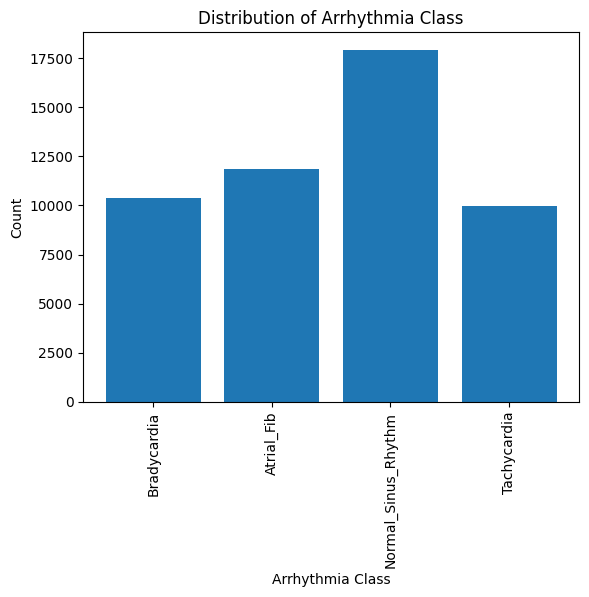

In [35]:
annotation_counter = Counter()
annotation_counter.update(y)

plt.bar(annotation_counter.keys(), annotation_counter.values())
plt.title('Distribution of Arrhythmia Class')
plt.xlabel('Arrhythmia Class')
plt.xticks(rotation=90)
plt.ylabel('Count')

In [36]:
# Label Encoding
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
num_classes = len(label_encoder.classes_)

In [37]:
# See label the mapping
mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
mapping = np.column_stack((label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print(mapping)

[['Atrial_Fib' '0']
 ['Bradycardia' '1']
 ['Normal_Sinus_Rhythm' '2']
 ['Tachycardia' '3']]


In [38]:
X_dwtcoeff_train, X_dwtcoeff_val, X_dwtmorph_train, X_dwtmorph_val, y_train, y_val = train_test_split(
    X_dwtcoeff, X_dwtmorph, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

In [39]:
# One-hot encoding for multi-class classification with softmax
y_train_cat = to_categorical(y_train)
y_val_cat = to_categorical(y_val)

### Model

In [40]:
# Input DWT → CNN + GRU
input_dwt = Input(shape=(X_dwtcoeff.shape[1], 1), name='dwtcoeff_input')
x = Conv1D(32, 3, activation='tanh')(input_dwt)
x = MaxPooling1D(2)(x)
x = Conv1D(16, 3, activation='tanh')(x)
x = MaxPooling1D(2)(x)
x = GRU(32, activation='tanh', return_sequences=True, unroll=True)(x)
x = GRU(16, activation='tanh', return_sequences=False, unroll=True)(x)
x = Dense(8, activation='tanh')(x)

# Input Morphological
input_features = Input(shape=(X_dwtmorph.shape[1],), name='dwtmorph_input')
y = Dense(8, activation='tanh')(input_features)

# Gabungkan
combined = Concatenate()([x, y])
z = Dense(8, activation='tanh')(combined)
output = Dense(num_classes, activation='softmax')(z)

model = Model(inputs=[input_dwt, input_features], outputs=output)
model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ dwtcoeff_input      │ (None, 125, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 123, 32)   │        128 │ dwtcoeff_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 61, 32)    │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 59, 16)    │      1,552 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 29, 16)    │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 29, 32)    │      4,800 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 16)        │      2,400 │ gru[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dwtmorph_input      │ (None, 39)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 8)         │        136 │ gru_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 8)         │        320 │ dwtmorph_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16)        │          0 │ dense[0][0],      │
│ (Concatenate)       │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 8)         │        136 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 4)         │         36 │ dense_2[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,508 (37.14 KB)

 Trainable params: 9,508 (37.14 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
# Define callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)

history = model.fit(
    [X_dwtcoeff_train, X_dwtmorph_train],
    y_train_cat,
    validation_data=([X_dwtcoeff_val, X_dwtmorph_val], y_val_cat),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop, lr_scheduler]
)

Epoch 1/50
627/627 ━━━━━━━━━━━━━━━━━━━━ 69s 36ms/step - accuracy: 0.4202 - loss: 1.2495 - val_accuracy: 0.6291 - val_loss: 0.8874 - learning_rate: 0.0010
Epoch 2/50
627/627 ━━━━━━━━━━━━━━━━━━━━ 33s 24ms/step - accuracy: 0.6564 - loss: 0.8193 - val_accuracy: 0.7400 - val_loss: 0.6459 - learning_rate: 0.0010
Epoch 3/50
627/627 ━━━━━━━━━━━━━━━━━━━━ 24s 30ms/step - accuracy: 0.7535 - loss: 0.6274 - val_accuracy: 0.7776 - val_loss: 0.5665 - learning_rate: 0.0010
Epoch 4/50
627/627 ━━━━━━━━━━━━━━━━━━━━ 20s 31ms/step - accuracy: 0.7864 - loss: 0.5487 - val_accuracy: 0.8044 - val_loss: 0.5009 - learning_rate: 0.0010
Epoch 5/50
627/627 ━━━━━━━━━━━━━━━━━━━━ 21s 32ms/step - accuracy: 0.8149 - loss: 0.4815 - val_accuracy: 0.8254 - val_loss: 0.4522 - learning_rate: 0.0010
Epoch 6/50
627/627 ━━━━━━━━━━━━━━━━━━━━ 19s 31ms/step - accuracy: 0.8427 - loss: 0.4168 - val_accuracy: 0.8626 - val_loss: 0.3718 - learning_rate: 0.0010
Epoch 7/50
627/627 ━━━━━━━━━━━━━━━━━━━━ 20s 31ms/step - accuracy: 0.8633 - l

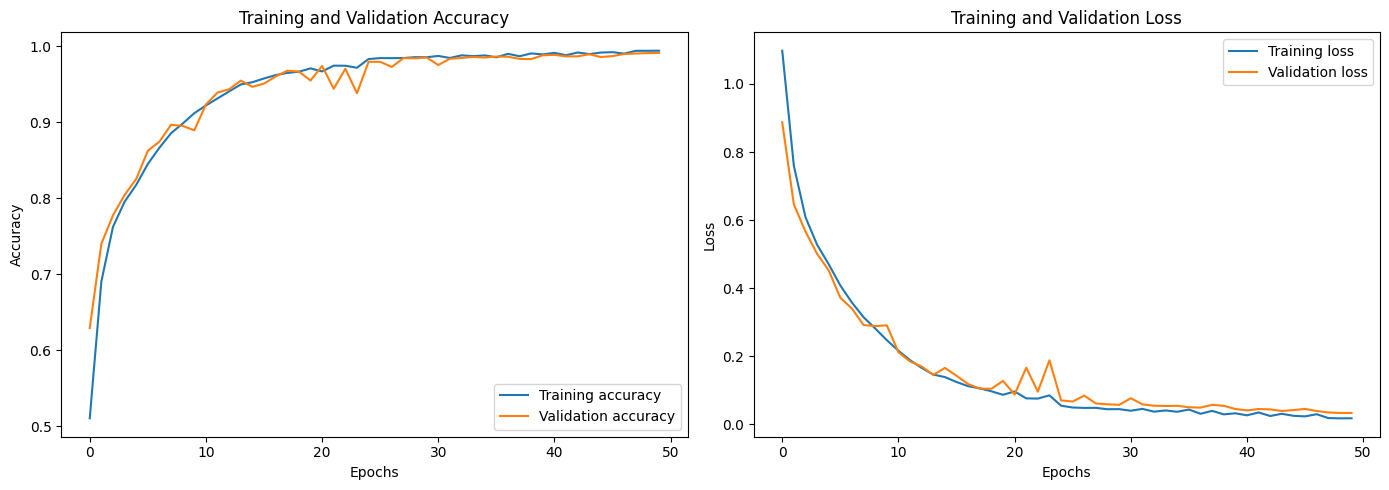

In [42]:
# Create figure and two subplot
plt.figure(figsize=(14, 5))

# Subplot 1: Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Subplot 2: Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Show plot
plt.tight_layout()
plt.show()

314/314 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9926 - loss: 0.0322
Validation accuracy: 0.9912272095680237
Loss: 0.03370358794927597
314/314 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step

Classification Report:
                     precision    recall  f1-score   support

         Atrial_Fib       0.99      0.99      0.99      2369
        Bradycardia       0.99      0.99      0.99      2077
Normal_Sinus_Rhythm       1.00      1.00      1.00      3587
        Tachycardia       0.98      0.98      0.98      1998

           accuracy                           0.99     10031
          macro avg       0.99      0.99      0.99     10031
       weighted avg       0.99      0.99      0.99     10031



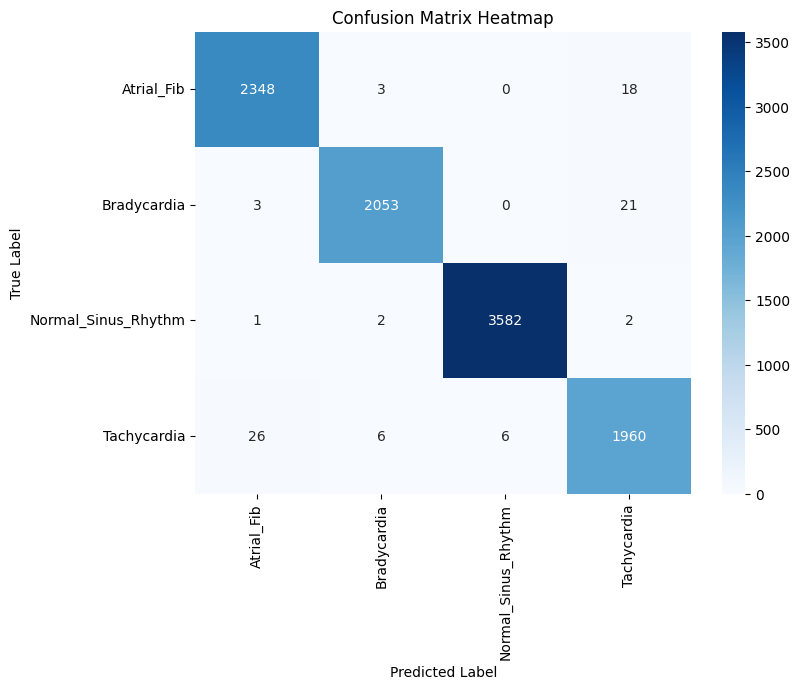

In [43]:
# Evaluate the model and print the accuracy
loss, accuracy = model.evaluate([X_dwtcoeff_val, X_dwtmorph_val], y_val_cat, verbose=1)
print(f'Validation accuracy: {accuracy}')
print(f'Loss: {loss}')

# Predict on test data
y_pred_prob = model.predict([X_dwtcoeff_val, X_dwtmorph_val])
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_val_cat, axis=1)

class_names = label_encoder.classes_

# Classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.xticks(rotation=90)
plt.ylabel('True Label')
plt.title('Confusion Matrix Heatmap')
plt.show()

### Save Model

In [44]:
model.save('MODEL_PPG_4C_DWT_MF_CNN_GRU_200.h5')
model.save('MODEL_PPG_4C_DWT_MF_CNN_GRU_200.keras')

In [54]:
from google.colab import files

In [55]:
files.download('MODEL_PPG_4C_DWT_MF_CNN_GRU_200.h5')
files.download('MODEL_PPG_4C_DWT_MF_CNN_GRU_200.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Export Model to TFLite

In [45]:
# Convert the model with Select TensorFlow Ops
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.experimental_new_converter = True
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,  # Use TensorFlow Lite ops
    tf.lite.OpsSet.SELECT_TF_OPS    # Enable TensorFlow ops
]
converter.allow_custom_ops = True
# converter._experimental_lower_tensor_list_ops = True  # Disable lowering tensor list ops
tflite_model = converter.convert()

# Save the model to a file
with open('MODEL_PPG_4C_DWT_MF_CNN_GRU_200.tflite', 'wb') as f:
    f.write(tflite_model)

print("TFLite model saved as 'MODEL_PPG_4C_DWT_MF_CNN_GRU_200.tflite'")

Saved artifact at '/tmp/tmpa3g67_qd'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 125, 1), dtype=tf.float32, name='dwtcoeff_input'), TensorSpec(shape=(None, 39), dtype=tf.float32, name='dwtmorph_input')]
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  132847623864976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132848383367056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132845776561808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132848383366864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132845776563920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132845776559888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132845776559504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132845776564880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132848383366288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1328457765

In [46]:
!apt-get -qq install xxd
!xxd -i MODEL_PPG_4C_DWT_MF_CNN_GRU_200.tflite > MODEL_PPG_4C_DWT_MF_CNN_GRU_200.cpp
!xxd -i MODEL_PPG_4C_DWT_MF_CNN_GRU_200.tflite > MODEL_PPG_4C_DWT_MF_CNN_GRU_200.h

In [56]:
files.download('MODEL_PPG_4C_DWT_MF_CNN_GRU_200.tflite')
files.download('MODEL_PPG_4C_DWT_MF_CNN_GRU_200.cpp')
files.download('MODEL_PPG_4C_DWT_MF_CNN_GRU_200.h')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Model Testing

### Input Data

In [48]:
!gdown -q 1NJrSBCSoEym-eAc5DRGgcogao53QVwZO

In [49]:
input_test = pd.read_json('PPG_DATASET_4CLASS_TEST_250Hz.json')

In [50]:
# Apply to the entire dataframe
input_test['ppg_signal_resampled'] = input_test.apply(
    lambda row: resample_signal(row['ppg_signal'], SAMPLING_RATE_ORIGIN, SAMPLING_RATE_TARGET), axis=1
)

input_test = input_test.drop(columns=['ppg_signal'])
input_test = input_test.rename(columns={'ppg_signal_resampled': 'ppg_signal'})
input_test = input_test[['ppg_signal', 'label']]

input_test.head()

,ppg_signal,label
0,"[3188.0981, 3453.5796, 2939.3435, 3048.354, 32...",Bradycardia
1,"[3269.0078, 3279.666, 3275.4924, 3278.0352, 32...",Bradycardia
2,"[3294.298, 3161.627, 3214.4055, 3182.5376, 320...",Bradycardia
3,"[4086.8796, 4179.051, 4117.047, 4149.1665, 411...",Bradycardia
4,"[3277.1252, 3276.956, 3277.026, 3276.9802, 327...",Bradycardia


In [51]:
input_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6066 entries, 0 to 6065
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   ppg_signal  6066 non-null   object
 1   label       6066 non-null   object
dtypes: object(2)
memory usage: 94.9+ KB


### Multiple Input Test

Count : 6065

Predicted true: 5857
Tested data: 6066

Accuracy: 96.55%

Classification Report:
                     precision    recall  f1-score   support

         Atrial_Fib       0.96      0.97      0.97      1920
        Bradycardia       0.98      0.96      0.97      1224
Normal_Sinus_Rhythm       0.99      0.99      0.99      1560
        Tachycardia       0.94      0.93      0.93      1362

           accuracy                           0.97      6066
          macro avg       0.97      0.96      0.96      6066
       weighted avg       0.97      0.97      0.97      6066



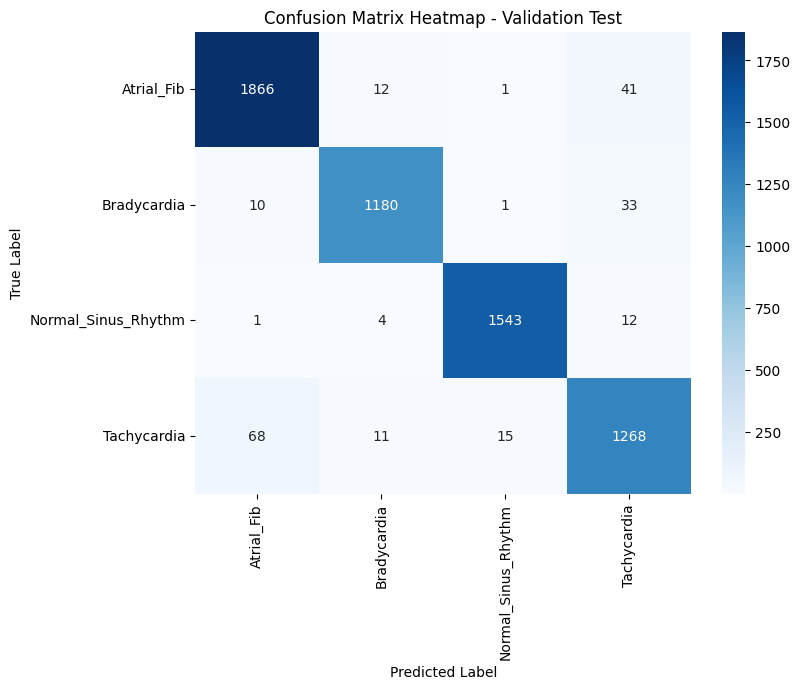

In [52]:
num_of_data = 6066
tested_data = 0
predicted_true = 0

true_labels = []
pred_labels = []

label_map = {
  0: "Atrial_Fib",
  1: "Bradycardia",
  2: "Normal_Sinus_Rhythm",
  3: "Tachycardia"
}

# Interpreter initialization
interpreter = Interpreter(model_path="MODEL_PPG_4C_DWT_MF_CNN_GRU_200.tflite")
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

for i in range(num_of_data):
    print(f"\rCount : {i}", end='', flush=True)

    # Load PPG signal
    data_test = input_test['ppg_signal'][i]

    fs = SAMPLING_RATE_TARGET
    row = {
        'ppg_signal': data_test,
        'frequency': fs
    }

    # Apply preprocessing
    processed_signal = preprocess_ppg_signal(row, norm_method='minmax', ma_window=5)
    data_test_preprocessing = processed_signal.tolist()

    # DWT decomposition
    dwtcoeff_input = extract_dwt_coeffs(data_test_preprocessing)
    dwtcoeff_input = np.expand_dims(dwtcoeff_input, axis=0)

    # DWT and Morphological features
    # data_dwt_features = []

    dwt_features = extract_dwt_features(data_test_preprocessing)
    if not any(np.isnan(val) for val in dwt_features):
        # data_test_features.extend(dwt_features)
        data_dwt_features = np.array([dwt_features], dtype=np.float32)
    else:
        # raise ValueError("NaN found in HRV features.")
        continue

    morph_features_list, _ = extract_morph_features(processed_signal, fs)

    for feature in morph_features_list:
        peak_array = [feature[key] for key in feature.keys()]
        if not any(np.isnan(val) for val in peak_array):
            morph_input = np.array([peak_array], dtype=np.float32)
            #  dwtmorph_input = np.concatenate([dwt_features, morph_input], axis=0)
            dwtmorph_input = np.concatenate([
                np.array(dwt_features, dtype=np.float32).reshape(1, -1),
                np.array(peak_array, dtype=np.float32).reshape(1, -1)
            ], axis=1)
            break
        else:
            continue

    # Convert to float32 as expected by model
    dwtcoeff_input = dwtcoeff_input.astype(np.float32)
    dwtmorph_input = dwtmorph_input.astype(np.float32)

    # Set input tensors
    for input_detail in input_details:
        name = input_detail['name']
        if 'dwtcoeff_input' in name:
            interpreter.resize_tensor_input(input_detail['index'], dwtcoeff_input.shape)
            interpreter.allocate_tensors()
            interpreter.set_tensor(input_detail['index'], dwtcoeff_input)
        elif 'dwtmorph_input' in name:
            interpreter.resize_tensor_input(input_detail['index'], dwtmorph_input.shape)
            interpreter.allocate_tensors()
            interpreter.set_tensor(input_detail['index'], dwtmorph_input)

    # Run inference
    interpreter.invoke()

    # Get output
    output_data = interpreter.get_tensor(output_details[0]['index'])
    predicted_class = np.argmax(output_data)

    true_label = input_test['label'][i]
    pred_label = label_map[predicted_class]

    true_labels.append(true_label)
    pred_labels.append(pred_label)

    if pred_label == true_label:
        predicted_true += 1

    tested_data += 1

print(f"\n\nPredicted true: {predicted_true}")
print(f"Tested data: {tested_data}")

accuracy = (predicted_true / tested_data) * 100
print(f"\nAccuracy: {accuracy:.2f}%")

class_names = list(label_map.values())

# Classification report
print("\nClassification Report:")
print(classification_report(true_labels, pred_labels, target_names=class_names))

# Confusion matrix with seaborn heatmap
cm = confusion_matrix(true_labels, pred_labels, labels=class_names)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.xticks(rotation=90)
plt.ylabel('True Label')
plt.title('Confusion Matrix Heatmap - Validation Test')
plt.show()

### Single test

In [53]:
INPUT_NUMBER = 1

label_map = {
  0: "Atrial_Fib",
  1: "Bradycardia",
  2: "Normal_Sinus_Rhythm",
  3: "Tachycardia"
}

# Interpreter initialization
interpreter = Interpreter(model_path="MODEL_PPG_4C_DWT_MF_CNN_GRU_200.tflite")
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Load PPG signal
data_test = input_test['ppg_signal'][INPUT_NUMBER]

fs = SAMPLING_RATE_TARGET
row = {
    'ppg_signal': data_test,
    'frequency': fs
}

# Apply preprocessing
processed_signal = preprocess_ppg_signal(row, norm_method='minmax', ma_window=5)
data_test_preprocessing = processed_signal.tolist()

# DWT decomposition
dwtcoeff_input = extract_dwt_coeffs(data_test_preprocessing)
dwtcoeff_input = np.expand_dims(dwtcoeff_input, axis=0)

# DWT and Morphological features
# data_dwt_features = []

dwt_features = extract_dwt_features(data_test_preprocessing)
if not any(np.isnan(val) for val in dwt_features):
    # data_test_features.extend(dwt_features)
    data_dwt_features = np.array([dwt_features], dtype=np.float32)

morph_features_list, _ = extract_morph_features(processed_signal, fs)

for feature in morph_features_list:
    peak_array = [feature[key] for key in feature.keys()]
    if not any(np.isnan(val) for val in peak_array):
        morph_input = np.array([peak_array], dtype=np.float32)
        #  dwtmorph_input = np.concatenate([dwt_features, morph_input], axis=0)
        dwtmorph_input = np.concatenate([
            np.array(dwt_features, dtype=np.float32).reshape(1, -1),
            np.array(peak_array, dtype=np.float32).reshape(1, -1)
        ], axis=1)
        break
    else:
        continue

# Convert to float32 as expected by model
dwtcoeff_input = dwtcoeff_input.astype(np.float32)
dwtmorph_input = dwtmorph_input.astype(np.float32)

# Set input tensors
for input_detail in input_details:
    name = input_detail['name']
    if 'dwtcoeff_input' in name:
        interpreter.resize_tensor_input(input_detail['index'], dwtcoeff_input.shape)
        interpreter.allocate_tensors()
        interpreter.set_tensor(input_detail['index'], dwtcoeff_input)
    elif 'dwtmorph_input' in name:
        interpreter.resize_tensor_input(input_detail['index'], dwtmorph_input.shape)
        interpreter.allocate_tensors()
        interpreter.set_tensor(input_detail['index'], dwtmorph_input)

# Run inference
interpreter.invoke()

# Get output
output_data = interpreter.get_tensor(output_details[0]['index'])
predicted_class = np.argmax(output_data)

print("True Label:", input_test['label'][INPUT_NUMBER])
print("Predicted Class:", predicted_class)
print("Predicted Label:", label_map[predicted_class])

True Label: Bradycardia
Predicted Class: 1
Predicted Label: Bradycardia
